# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'ahuwer2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

Om=0.1: max |table - astropy| = 2.63e-09 mag
Om=0.3: max |table - astropy| = 3.24e-09 mag
Om=0.5: max |table - astropy| = 6.78e-09 mag
Om=0.9: max |table - astropy| = 3.11e-08 mag


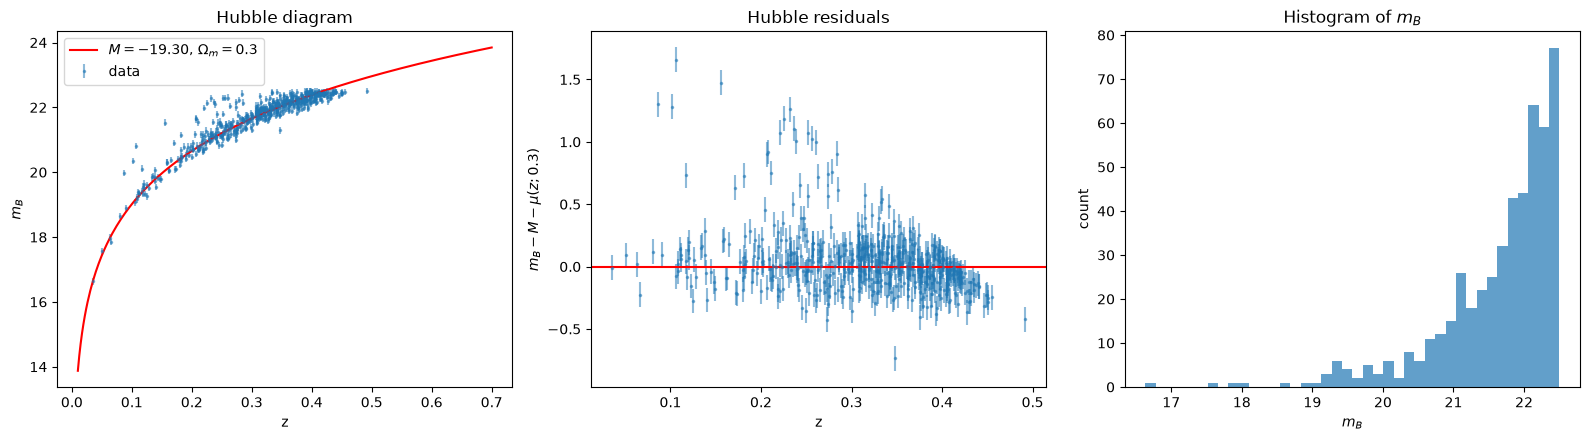

Maximum found m_B: 22.50 at z=0.492
acceptance at (Om=0.3, f=0.1): 0.206


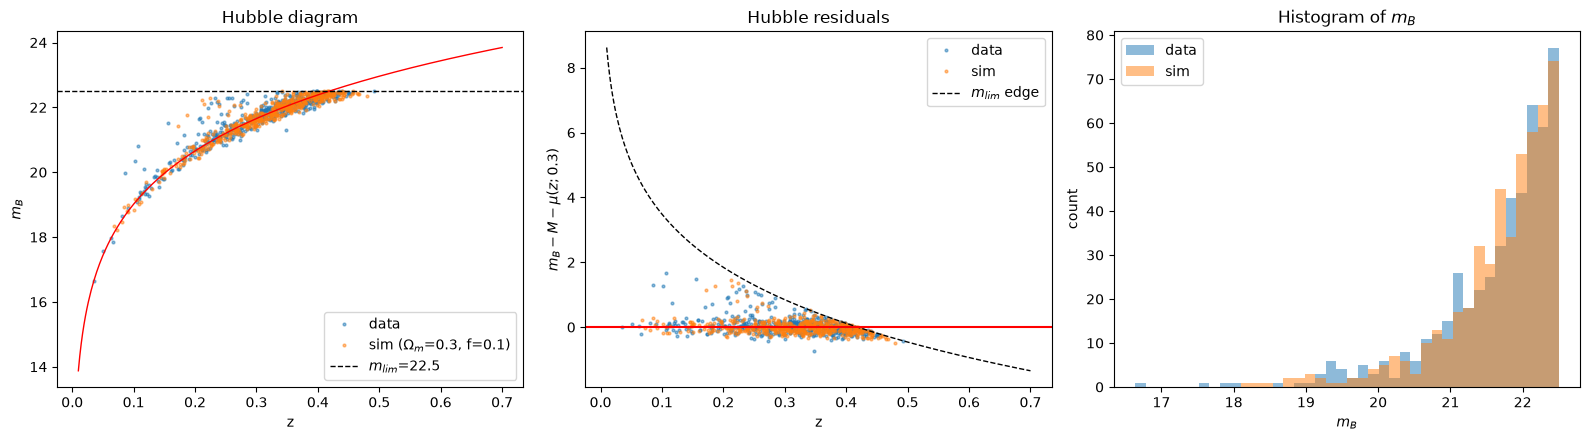

In [2]:
# Part 1: your work here
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import RegularGridInterpolator

# ----------------------------------------------------------------
# Constants
# ----------------------------------------------------------------
C_KMS = 299792.458      # speed of light, km/s
H0 = 70.0               # km/s/Mpc
M_IA, SIG_M_IA = -19.30, 0.12
M_CC, SIG_M_CC = -18.5, 0.5
SIG_MEAS = 0.10
Z_MIN, Z_MAX = 0.01, 0.7
N_SN = 500

# ----------------------------------------------------------------
# Part 1: Hubble diagram, residuals, histogram
# ----------------------------------------------------------------
# Tabulate mu(z; Om) first (needed for the residuals too).
z_grid = np.linspace(0.0, 0.75, 3001)          # fine grid in z
Om_grid = np.arange(0.0, 1.0 + 1e-9, 0.005)    # spacing 0.005 in Om

def _build_mu_table(z_grid, Om_grid):
    table = np.empty((len(Om_grid), len(z_grid)))
    for i, Om in enumerate(Om_grid):
        E = np.sqrt(Om * (1 + z_grid) ** 3 + 1 - Om)
        # comoving integral of 1/E from 0 to z
        I = cumulative_trapezoid(1.0 / E, z_grid, initial=0.0)
        dL = (1 + z_grid) * (C_KMS / H0) * I          # Mpc
        with np.errstate(divide="ignore"):
            table[i] = 5 * np.log10(dL * 1e6 / 10.0)   # d_L in pc / 10 pc
    table[:, 0] = table[:, 1]   # z=0 is -inf; never used (z >= 0.01)
    return table

mu_table = _build_mu_table(z_grid, Om_grid)
_mu_interp = RegularGridInterpolator((Om_grid, z_grid), mu_table, method="linear")

def mu(z, Om):
    """Distance modulus mu(z; Om) for flat LCDM, H0=70, via table interpolation.
    z: array; Om: scalar."""
    z = np.asarray(z)
    pts = np.column_stack([np.full(z.shape, Om), z])
    return _mu_interp(pts)

# Check the table against astropy at a few points
from astropy.cosmology import FlatLambdaCDM
for Om_t in [0.1, 0.3, 0.5, 0.9]:
    zt = np.array([0.01, 0.1, 0.3, 0.7])
    ap = FlatLambdaCDM(H0=70, Om0=Om_t).distmod(zt).value
    print(f"Om={Om_t}: max |table - astropy| = {np.max(np.abs(mu(zt, Om_t) - ap)):.2e} mag")

# Data
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

# Hubble residuals relative to the fiducial Ia + Om=0.3
resid = m - M_IA - mu(z, 0.3)

zz = np.linspace(Z_MIN, Z_MAX, 300)
mu_fid = mu(zz, 0.3) + M_IA

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
ax.errorbar(z, m, yerr=sig_m, fmt='.', ms=3, alpha=0.5, label='data')
ax.plot(zz, mu_fid, 'r-', label=r'$M=-19.30$, $\Omega_m=0.3$')
ax.set_xlabel('z'); ax.set_ylabel(r'$m_B$'); ax.set_title('Hubble diagram')
ax.legend()

ax = axes[1]
ax.errorbar(z, resid, yerr=sig_m, fmt='.', ms=3, alpha=0.5)
ax.axhline(0, color='r')
ax.set_xlabel('z'); ax.set_ylabel(r'$m_B - M - \mu(z;0.3)$')
ax.set_title('Hubble residuals')

ax = axes[2]
ax.hist(m, bins=40, color='C0', alpha=0.7)
ax.set_xlabel(r'$m_B$'); ax.set_ylabel('count'); ax.set_title(r'Histogram of $m_B$')

plt.tight_layout()
plt.show()

print(f"Maximum found m_B: {np.max(m):.2f} at z={z[np.argmax(m)]:.3f}")

# ----------------------------------------------------------------
# Part 3: simulator, now with the magnitude cut
# ----------------------------------------------------------------
M_LIM = 22.5   # survey limit, read off the data; the survey keeps m_B < M_LIM

_z3_lo, _z3_hi = Z_MIN ** 3, Z_MAX ** 3

def _draw_batch(Om, f, rng, size):
    """Draw `size` supernovae from the full population (no cut)."""
    u = rng.random(size)
    z_b = (_z3_lo + u * (_z3_hi - _z3_lo)) ** (1.0 / 3.0)   # p(z) ∝ z^2

    is_cc = rng.random(size) < f                             # impostor flag ~ Bernoulli(f)
    M = np.where(is_cc, M_CC, M_IA) + np.where(is_cc, SIG_M_CC, SIG_M_IA) * rng.standard_normal(size)

    m_b = M + mu(z_b, Om) + SIG_MEAS * rng.standard_normal(size)
    return z_b, m_b

def simulate(Om, f, rng, n=N_SN, m_lim=M_LIM, return_N=False):
    """Fake file like the data: n supernovae that passed the cut m_B < m_lim.

    Supernovae are drawn from the full population and the ones above m_lim
    are thrown away, repeating until n survive. The first n survivors of an
    iid stream are an exact iid sample of the detected population, so no
    reweighting is needed.
    """
    z_keep, m_keep, n_drawn = [], [], 0
    batch = 3 * n                                  # a first guess; acceptance is ~30-50%
    for _ in range(200):                           # safety cap
        z_b, m_b = _draw_batch(Om, f, rng, batch)
        n_drawn += batch
        ok = m_b < m_lim                           # I_i = 1
        z_keep.append(z_b[ok]); m_keep.append(m_b[ok])
        if sum(len(a) for a in z_keep) >= n:
            break
    else:
        raise RuntimeError("acceptance too low; check Om, f, m_lim")

    z_out = np.concatenate(z_keep)[:n]
    m_out = np.concatenate(m_keep)[:n]
    if return_N:
        # number drawn up to the n-th survivor, to the nearest batch (rough N)
        return z_out, m_out, n_drawn
    return z_out, m_out

# Quick check: what fraction of the population survives the cut at the guess?
rng = np.random.default_rng(42)
Om_guess, f_guess = 0.3, 0.1
_zt, _mt = _draw_batch(Om_guess, f_guess, rng, 200_000)
print(f"acceptance at (Om={Om_guess}, f={f_guess}): {np.mean(_mt < M_LIM):.3f}")

# One simulation over the data, same three panels as part 1
z_s, m_s = simulate(Om_guess, f_guess, rng)
resid_s = m_s - M_IA - mu(z_s, 0.3)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
ax.plot(z, m, '.', ms=4, alpha=0.5, label='data')
ax.plot(z_s, m_s, '.', ms=4, alpha=0.5, color='C1',
        label=f'sim ($\\Omega_m$={Om_guess}, f={f_guess})')
ax.plot(zz, mu_fid, 'r-', lw=1)
ax.axhline(M_LIM, color='k', ls='--', lw=1, label=f'$m_{{lim}}$={M_LIM}')
ax.set_xlabel('z'); ax.set_ylabel(r'$m_B$'); ax.set_title('Hubble diagram')
ax.legend()

ax = axes[1]
ax.plot(z, resid, '.', ms=4, alpha=0.5, label='data')
ax.plot(z_s, resid_s, '.', ms=4, alpha=0.5, color='C1', label='sim')
ax.plot(zz, M_LIM - M_IA - mu(zz, 0.3), 'k--', lw=1, label=r'$m_{lim}$ edge')
ax.axhline(0, color='r')
ax.set_xlabel('z'); ax.set_ylabel(r'$m_B - M - \mu(z;0.3)$')
ax.set_title('Hubble residuals'); ax.legend()

ax = axes[2]
bins = np.histogram_bin_edges(np.concatenate([m, m_s]), bins=40)
ax.hist(m, bins=bins, alpha=0.5, label='data')
ax.hist(m_s, bins=bins, alpha=0.5, color='C1', label='sim')
ax.set_xlabel(r'$m_B$'); ax.set_ylabel('count'); ax.set_title(r'Histogram of $m_B$')
ax.legend()

plt.tight_layout()
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

1. I see that for the most part, the data follows the curve expected of $\Omega_m=0.3$. There are however some outliers, especially around $z=0.3$ and below, where we see significantly higher than expected $m_B$ indicating that we do indeed have contaminants in our dataset. We can also very clearly see a sharp cutoff to the data above a certain $m_B$ value (which as printed above is $m_B=22.5$), indicating the presence of Malmquist bias. To deal with it, I've decided to simply add that bias to the simulation and model so that any summary statistics or simulated data in later parts behaves the same as our obtained data.
2. See the image below:
<img src="lab09_PGM.png" alt="Probabalistic Graphical Model for problem 1.2" width="700" style="display:block;margin:15px auto;max-width:100%">
The latent quantities are $N$, the impostor check value (1 for impostor and 0 for Ia), and the mass $M_i=M_{Ia}$ *or* $M_i=M_{impostor}$ depending on whether its an impostor or not. $f$ simply enters the impostor check, as each data point has the probability to be an impostor given by $0\leq f\leq 1.$
3. Results are shown above, and after accounting for the truncated data we see a very clear overlap indicating our simulation is working properly.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

scan minimum at Om = 0.2635  (minimize_scalar: 0.2634)
Om_hat = 0.2634
chi2_min = 1608.5 for 499 dof (chi2/dof = 3.22)
68% interval: [0.2500, 0.2769]
Om = 0.2634 +0.0135 / -0.0134


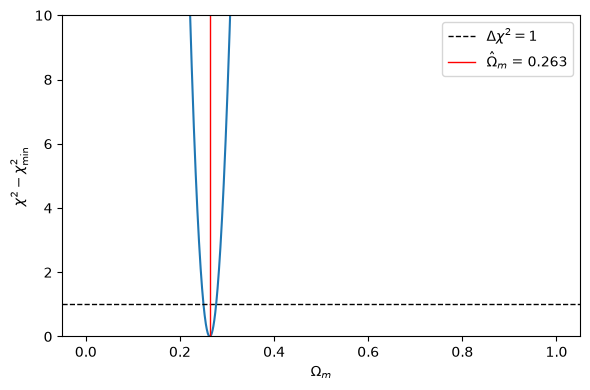

In [3]:
# Part 2: your work here
from scipy.optimize import minimize_scalar, brentq

# ----------------------------------------------------------------
# Part: chi^2 fit of Om, pretending every supernova is a Ia
# ----------------------------------------------------------------
SIG_TOT2 = SIG_M_IA**2 + SIG_MEAS**2       # 0.12^2 + 0.10^2

def chi2(Om):
    r = m - M_IA - mu(z, Om)
    return np.sum(r**2) / SIG_TOT2

# Minimize (bounded to the range of the mu table)
res = minimize_scalar(chi2, bounds=(Om_grid[0], Om_grid[-1]), method='bounded',
                      options={'xatol': 1e-8})
Om_hat, chi2_min = res.x, res.fun

# Cross-check with a brute-force scan (guards against a local minimum)
Om_scan = np.linspace(Om_grid[0], Om_grid[-1], 2001)
chi2_scan = np.array([chi2(o) for o in Om_scan])
print(f"scan minimum at Om = {Om_scan[np.argmin(chi2_scan)]:.4f}  (minimize_scalar: {Om_hat:.4f})")

# 1 sigma interval from Delta chi^2 = 1
def _crossing(lo, hi):
    g = lambda o: chi2(o) - chi2_min - 1.0
    if g(lo) * g(hi) > 0:
        return None                          # no crossing inside the allowed range
    return brentq(g, lo, hi, xtol=1e-10)

Om_lo = _crossing(Om_grid[0], Om_hat)
Om_hi = _crossing(Om_hat, Om_grid[-1])

print(f"Om_hat = {Om_hat:.4f}")
print(f"chi2_min = {chi2_min:.1f} for {len(z) - 1} dof (chi2/dof = {chi2_min/(len(z)-1):.2f})")
if Om_lo is not None and Om_hi is not None:
    print(f"68% interval: [{Om_lo:.4f}, {Om_hi:.4f}]")
    print(f"Om = {Om_hat:.4f} +{Om_hi - Om_hat:.4f} / -{Om_hat - Om_lo:.4f}")
else:
    print("Delta chi^2 = 1 not reached inside [0, 1] on at least one side; "
          "the interval is truncated by the prior range.")

# Plot chi^2 vs Om with the Delta chi^2 = 1 level
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(Om_scan, chi2_scan - chi2_min)
ax.axhline(1, color='k', ls='--', lw=1, label=r'$\Delta\chi^2 = 1$')
ax.axvline(Om_hat, color='r', lw=1, label=rf'$\hat\Omega_m$ = {Om_hat:.3f}')
ax.set_ylim(0, 10)
ax.set_xlabel(r'$\Omega_m$'); ax.set_ylabel(r'$\chi^2 - \chi^2_{\min}$')
ax.legend()
plt.tight_layout(); plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

The naive fit gives $\operatorname{min}(\chi^2)=1608.5$, $\chi^2/\text{dof}=3.22,$ and $\hat{\Omega}_m=0.2634\pm0.0135$.

I expect that the impostors are pushing $\hat\Omega_m$ low in this naive fit. We can see them on the Hubble diagram from part 1, they're the points that sit above the Ia ridge line, with positive residuals in the residual panel (up to around 1.5 mag at the maximum). The contaminant data points are fainter than the Ia data at the same $z$ ($M \approx -18.5$ vs $-19.30$), so their observed $m_B$ is larger than the naive Ia model predicts. If we leave $M$ fixed at $-19.30$, the only way the fit can work around a larger $m_B$ is by increasing the distance modulus $\mu$, and thus the distance $d_L$. In a flat $\Lambda\text{CDM}$ universe, lowering $\Omega_m$ raises $\Omega_\Lambda$, which increases the acceleration and the distance light travels for a given $z$, so $d_L$ and $\mu$ increase, which is exatcly the same contaminant effect I just described. Thus the impostors should therefore pull the fit towards a lower $\Omega_m$ value.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

data: median residual = 0.0047 mag, fraction > 0.5 mag = 0.0580


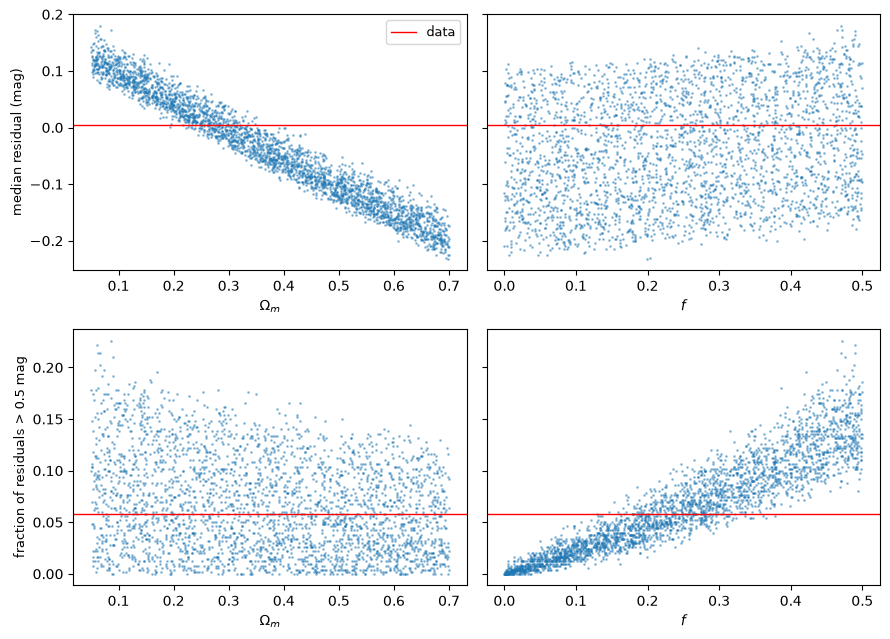

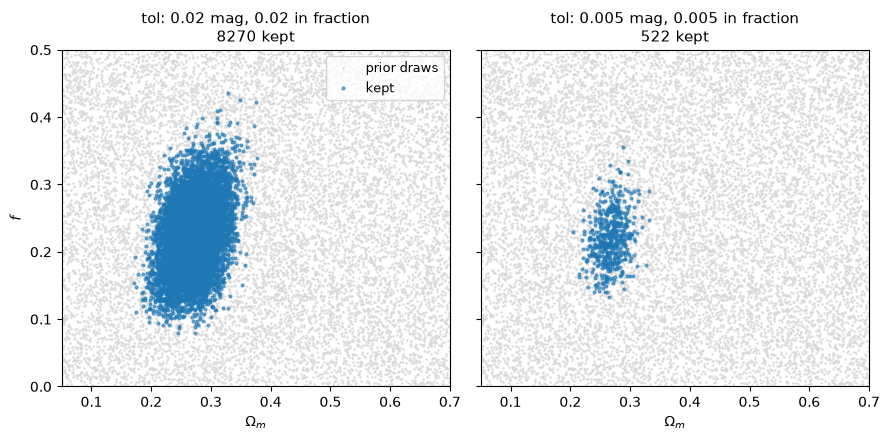

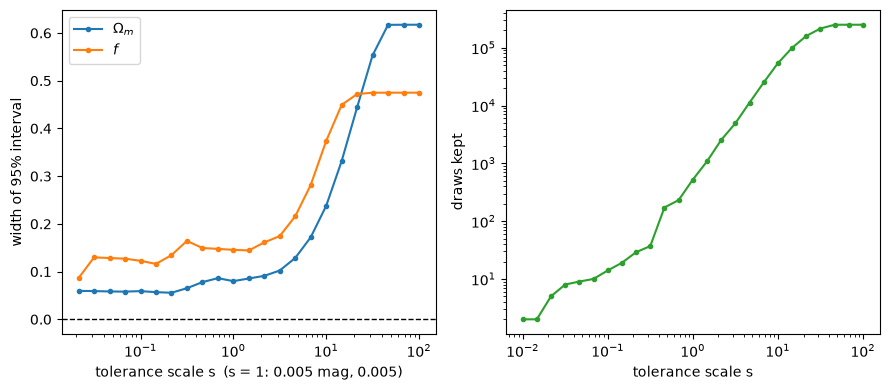

tolerance = 0.005 mag, 0.005: kept 522 of 250000 (0.21%)
Omega_m : median 0.267, 95% interval [0.227, 0.307]   (kept within 5% of prior edges: 0.0% low, 0.0% high)
f       : median 0.219, 95% interval [0.153, 0.298]   (kept within 5% of prior edges: 0.0% low, 0.0% high)
chi^2 fit (all-Ia assumption): Om_hat = 0.263 +0.013 / -0.013


In [4]:
# Part 3: your work here
import os
# ----------------------------------------------------------------
# ABC setup: summaries, prior simulations (cached)
# ----------------------------------------------------------------
SEED = 100
N_SIM = 250000
OM_RANGE, F_RANGE = (0.05, 0.70), (0.0, 0.5)  # flat priors
R_THR = 0.5                                  # mag above the Ia ridge counted as "clearly too faint to be a Ia"
CACHE = f'abc_sims_seed{SEED}_n{N_SIM}.npz'

SUM_NAMES = ['median residual (mag)', f'fraction of residuals > {R_THR} mag']

def summaries(z_, m_):
    """The two summaries of one dataset. Residuals use the fixed fiducial Om=0.3, M=-19.30."""
    r = m_ - M_IA - mu(z_, 0.3)
    return np.array([np.median(r), np.mean(r > R_THR)])

def run_prior_sims(n_sim, seed):
    rng_abc = np.random.default_rng(seed)
    theta_ = np.column_stack([rng_abc.uniform(*OM_RANGE, n_sim),
                              rng_abc.uniform(*F_RANGE, n_sim)])
    S_ = np.empty((n_sim, 2))
    for i, (Om_i, f_i) in enumerate(theta_):
        z_i, m_i = simulate(Om_i, f_i, rng_abc)
        S_[i] = summaries(z_i, m_i)
    return theta_, S_

# Simulate once, then reuse. Delete the file if you change the simulator, M_LIM, or the summaries.
_ok = False
if os.path.exists(CACHE):
    _c = np.load(CACHE)
    _ok = bool(_c['m_lim'] == M_LIM) and _c['theta'].shape[0] == N_SIM and _c['S'].shape[1] == 2
if _ok:
    theta, S_sim = _c['theta'], _c['S']
else:
    theta, S_sim = run_prior_sims(N_SIM, SEED)
    np.savez_compressed(CACHE, theta=theta, S=S_sim, m_lim=M_LIM)

S_obs = summaries(z, m)                                  # the same summaries, on your file
print(f"data: median residual = {S_obs[0]:.4f} mag, fraction > {R_THR} mag = {S_obs[1]:.4f}")

# ----------------------------------------------------------------
# 1. Each summary against Om and against f (first 3000 prior simulations); red line = data
# ----------------------------------------------------------------
def plot_summary_response(n_show=3000):
    fig, axes = plt.subplots(2, 2, figsize=(9, 6.5), sharey='row')
    for k, nm in enumerate(SUM_NAMES):
        for col, (j, lab) in enumerate([(0, r'$\Omega_m$'), (1, r'$f$')]):
            ax = axes[k, col]
            ax.plot(theta[:n_show, j], S_sim[:n_show, k], '.', ms=2, alpha=0.4)
            ax.axhline(S_obs[k], color='r', lw=1, label='data' if (k, col) == (0, 0) else None)
            ax.set_xlabel(lab)
    axes[0, 0].set_ylabel(SUM_NAMES[0], fontsize=9)
    axes[1, 0].set_ylabel(SUM_NAMES[1], fontsize=9)
    axes[0, 0].legend(fontsize=9)
    plt.tight_layout(); plt.show()

plot_summary_response()

# ----------------------------------------------------------------
# 2. Rejection ABC, tolerances in each summary's own units (as on Nov 3):
#    keep a draw if BOTH |S_sim - S_obs| <= tolerance, with a separate tolerance per summary
# ----------------------------------------------------------------
def keep(tol):
    """tol = (tolerance on median residual in mag, tolerance on the fraction)."""
    return np.all(np.abs(S_sim - S_obs) <= np.asarray(tol), axis=1)

# two tolerances to show (placeholders: loose, then tight)
TOL_A = (0.02, 0.02)
TOL_B = (0.005, 0.005)

def plot_kept(tol_list):
    fig, axes = plt.subplots(1, len(tol_list), figsize=(9, 4.5), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, tol in zip(axes, tol_list):
        kk = keep(tol)
        ax.plot(theta[::20, 0], theta[::20, 1], '.', ms=1.5, color='0.85', rasterized=True, label='prior draws')
        ax.plot(theta[kk, 0], theta[kk, 1], '.', ms=4, color='C0', alpha=0.6, label='kept')
        ax.set_xlim(OM_RANGE); ax.set_ylim(F_RANGE)
        ax.set_xlabel(r'$\Omega_m$')
        ax.set_title(f'tol: {tol[0]} mag, {tol[1]} in fraction\n{kk.sum()} kept', fontsize=11)
    axes[0].set_ylabel(r'$f$'); axes[0].legend(loc='upper right', fontsize=9)
    plt.tight_layout(); plt.show()

plot_kept([TOL_A, TOL_B])

# ----------------------------------------------------------------
# 3. Scan the tolerance to help choose: shrink both tolerances together by a factor s
# ----------------------------------------------------------------
TOL_BASE = np.array(TOL_B)
scales = np.logspace(-2, 2, 25)
n_kept, widths = [], []
for s in scales:
    kk = keep(TOL_BASE * s)
    n_kept.append(kk.sum())
    widths.append([np.diff(np.quantile(theta[kk, j], [0.025, 0.975]))[0] if kk.sum() >= 5 else np.nan
                   for j in (0, 1)])
n_kept, widths = np.array(n_kept), np.array(widths)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].plot(scales, widths[:, 0], 'o-', ms=3, label=r'$\Omega_m$')
axes[0].plot(scales, widths[:, 1], 'o-', ms=3, label=r'$f$')
axes[0].axhline(0, color='k', ls='--', lw=1)
axes[0].set_xscale('log'); axes[0].set_xlabel(f'tolerance scale s  (s = 1: {TOL_B[0]} mag, {TOL_B[1]})')
axes[0].set_ylabel('width of 95% interval'); axes[0].legend()
axes[1].plot(scales, n_kept, 'o-', ms=3, color='C2')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('tolerance scale s'); axes[1].set_ylabel('draws kept')
plt.tight_layout(); plt.show()

# ----------------------------------------------------------------
# Posterior at the final tolerance (set this after looking at the plots above)
# ----------------------------------------------------------------
TOL_FINAL = TOL_B
kept = keep(TOL_FINAL)
print(f"tolerance = {TOL_FINAL[0]} mag, {TOL_FINAL[1]}: kept {kept.sum()} of {N_SIM} ({kept.mean():.2%})")
for j, nm, (a, b) in [(0, 'Omega_m', OM_RANGE), (1, 'f', F_RANGE)]:
    lo, med, hi = np.quantile(theta[kept, j], [0.025, 0.5, 0.975])
    edge = 0.05 * (b - a)
    print(f"{nm:8s}: median {med:.3f}, 95% interval [{lo:.3f}, {hi:.3f}]   "
          f"(kept within 5% of prior edges: {np.mean(theta[kept, j] < a + edge):.1%} low, "
          f"{np.mean(theta[kept, j] > b - edge):.1%} high)")

# Compare Om with the chi^2 fit from the previous section
if 'Om_hat' in globals():
    lo_s = f"-{Om_hat - Om_lo:.3f}" if Om_lo is not None else "(no lower crossing)"
    hi_s = f"+{Om_hi - Om_hat:.3f}" if Om_hi is not None else "(no upper crossing)"
    print(f"chi^2 fit (all-Ia assumption): Om_hat = {Om_hat:.3f} {hi_s} / {lo_s}")

In [5]:
for s in [2, 1.4, 1, 0.7, 0.5]:
    kk = keep(TOL_BASE * s)
    lo, med, hi = np.quantile(theta[kk], [0.025, 0.5, 0.975], axis=0)
    print(f"s={s:<4} kept={kk.sum():5d}  Om {med[0]:.3f} [{lo[0]:.3f}, {hi[0]:.3f}]   f {med[1]:.3f} [{lo[1]:.3f}, {hi[1]:.3f}]")

s=2    kept= 1901  Om 0.269 [0.225, 0.314]   f 0.220 [0.150, 0.303]
s=1.4  kept= 1025  Om 0.268 [0.227, 0.312]   f 0.219 [0.154, 0.298]
s=1    kept=  522  Om 0.267 [0.227, 0.307]   f 0.219 [0.153, 0.298]
s=0.7  kept=  235  Om 0.268 [0.223, 0.308]   f 0.217 [0.153, 0.300]
s=0.5  kept=  183  Om 0.270 [0.224, 0.305]   f 0.217 [0.154, 0.302]


**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

1. The summary statistics I chose were a) the median residual, and b) the fraction of residuals which were $>0.5$ mag. I chose the median residual intending it to vary more in $\Omega_m$ than $f$ as changing $\Omega_m$ would shift the curve used for calculating the residual and thus should effect all residuals (and thus their median) similarly. As for the second summary statistic, I chose the fraction of residuals above a threshold magnitude of $0.5$ as we could clearly see in part 1 that the contaminants were most obvious above a residual of 0.5 mag. If there were a higher fraction of contaminants, we would thus expect to see a similarly high number of data points with residuals above this threshold.
2. Since the summary statistics have different units (mag vs dimensionless) and we can't easily take the Euclidean distance, I simply chose to use a box tolerance, i.e. data was kept if both summary statistics were within the specified tolerance. You can see the effect of the values chosen in the plot above, and I stuck with the values in the rightmost subplot for the rest of the assignment. 
3. I found the posterior (given $\epsilon=0.005$ in both axes) to have $\operatorname{median}(\Omega_m)=0.267$ with $95\%$ interval [0.227, 0.307], and $\operatorname{median}(f)=0.219$ with $95\%$ interval [0.153, 0.298]. 
I believe that specific choice of $\epsilon$ values to be close to ideal thanks to the final set of plots. Specifically, we see that as we scale down the tolerance in both axes from the chosen value, the width of the interval continues to decrease at a much slower rate than you would see by scaling down *to* the chosen value, while the number of draws kept decreases almost exponentially. Decreasing the tolerances any further may slightly decrease the width of the 95% interval, but it would be less trustworthy as we would be considering on the order of $10^1$ points rather than order $10^2$.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

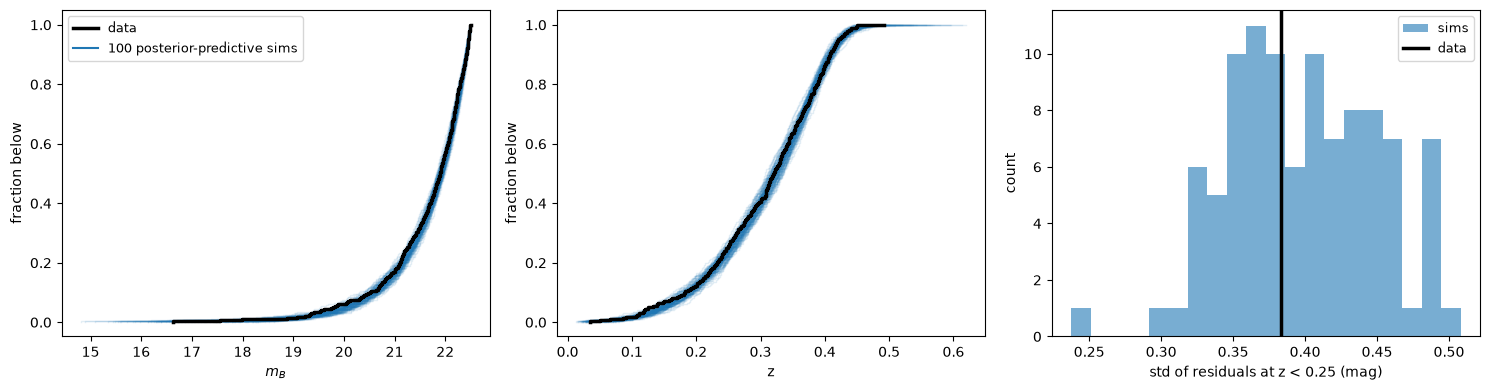

statistic                         data         sim median [16, 84]  p (sim >= data)
median m_B                     21.9041    21.9102 [21.8672, 21.9541]             0.60
resid scatter (z<0.25)          0.3835     0.3935 [0.3521, 0.4518]             0.58
90th pct z                      0.4077     0.4080 [0.4042, 0.4124]             0.56
mean resid                      0.0442     0.0510 [0.0328, 0.0698]             0.62
300 of 300 tests had at least 30 kept draws (median 527 kept per test)
Omega_m : 95% interval contains the truth in 94.3% of tests (binomial error ~1.3%)
f       : 95% interval contains the truth in 96.0% of tests (binomial error ~1.1%)


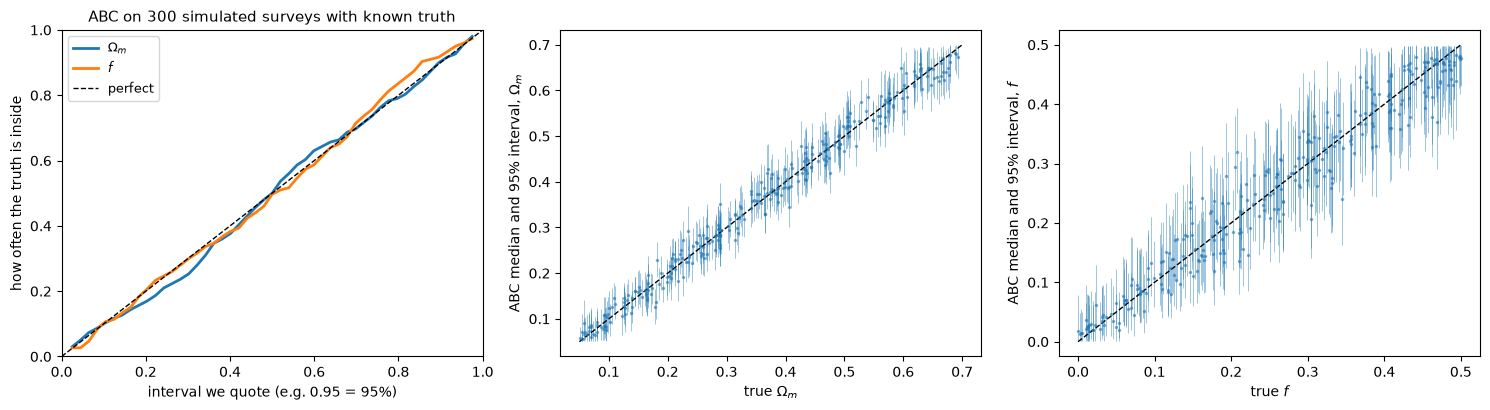

In [6]:
# Part 4: your work here
# ----------------------------------------------------------------
# 1. Posterior predictive check
# ----------------------------------------------------------------
N_PPC = 100
Z_LOW = 0.25
rng_ppc = np.random.default_rng(123)

kept_idx = np.flatnonzero(keep(TOL_FINAL))
ppc_idx = rng_ppc.choice(kept_idx, size=N_PPC, replace=False)
ppc_sims = [simulate(theta[i, 0], theta[i, 1], rng_ppc) for i in ppc_idx]   # list of (z, m_B), one per kept draw

def check_stats(z_, m_):
    """Statistics the ABC summaries did NOT use (median residual and the fraction > R_THR were used)."""
    r = m_ - M_IA - mu(z_, 0.3)
    lo = z_ < Z_LOW
    return {'median m_B': np.median(m_),
            f'resid scatter (z<{Z_LOW})': np.std(r[lo]),
            '90th pct z': np.quantile(z_, 0.9),
            'mean resid': np.mean(r)}

stats_data = check_stats(z, m)
stats_sim = {k: np.array([check_stats(zs, ms)[k] for zs, ms in ppc_sims]) for k in stats_data}

def ecdf(x):
    x = np.sort(x)
    return x, np.arange(1, len(x) + 1) / len(x)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]                                       # ECDF of m_B
for zs, ms in ppc_sims:
    ax.step(*ecdf(ms), color='C0', alpha=0.12, lw=1)
ax.step(*ecdf(m), color='k', lw=2.5, label='data')
ax.step([], [], color='C0', label=f'{N_PPC} posterior-predictive sims')
ax.set_xlabel(r'$m_B$'); ax.set_ylabel('fraction below'); ax.legend(loc='upper left', fontsize=9)

ax = axes[1]                                       # ECDF of z
for zs, ms in ppc_sims:
    ax.step(*ecdf(zs), color='C0', alpha=0.12, lw=1)
ax.step(*ecdf(z), color='k', lw=2.5)
ax.set_xlabel('z'); ax.set_ylabel('fraction below')

ax = axes[2]                                       # low-z residual scatter
key = f'resid scatter (z<{Z_LOW})'
ax.hist(stats_sim[key], bins=20, color='C0', alpha=0.6, label='sims')
ax.axvline(stats_data[key], color='k', lw=2.5, label='data')
ax.set_xlabel(f'std of residuals at z < {Z_LOW} (mag)'); ax.set_ylabel('count'); ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

# Posterior predictive p-values: fraction of simulations at or above the data's value.
# Values near 0 or 1 mean the data sit in a tail of what the fitted model predicts.
print(f"{'statistic':28s} {'data':>9s}  {'sim median [16, 84]':>26s}  {'p (sim >= data)':>15s}")
for k, v in stats_data.items():
    s = stats_sim[k]
    p16, p50, p84 = np.quantile(s, [0.16, 0.5, 0.84])
    print(f"{k:28s} {v:9.4f}  {p50:9.4f} [{p16:.4f}, {p84:.4f}]  {np.mean(s >= v):15.2f}")

# ----------------------------------------------------------------
# 2. Coverage: treat prior simulations as the data, run the same ABC with all the others
# ----------------------------------------------------------------
N_TEST = 300                                       # at least 20; more makes the coverage estimate less noisy
MIN_KEPT_COV = 30                                  # skip a test if the tolerance box catches fewer draws than this
rng_cov = np.random.default_rng(1234)
test_idx = rng_cov.choice(N_SIM, size=N_TEST, replace=False)
tol_arr = np.asarray(TOL_FINAL)

truth, rank_u, post_q, n_kept_t = [], [], [], []
for t in test_idx:
    kk = np.all(np.abs(S_sim - S_sim[t]) <= tol_arr, axis=1)    # the same ABC, with S_sim[t] as the "data"
    kk[t] = False                                                # leave the test simulation out of its own posterior
    if kk.sum() < MIN_KEPT_COV:
        continue
    th_k = theta[kk]
    truth.append(theta[t])
    rank_u.append(np.mean(th_k < theta[t], axis=0))              # fraction of the posterior below the truth
    post_q.append(np.quantile(th_k, [0.025, 0.5, 0.975], axis=0))
    n_kept_t.append(kk.sum())

truth, rank_u, post_q = np.array(truth), np.array(rank_u), np.array(post_q)   # (n, 2), (n, 2), (n, 3, 2)
n_valid = len(truth)
print(f"{n_valid} of {N_TEST} tests had at least {MIN_KEPT_COV} kept draws "
      f"(median {int(np.median(n_kept_t))} kept per test)")

# The central L interval holds the truth iff the truth's rank u is within L/2 of the middle
levels = np.linspace(0.025, 0.975, 49)
cover = np.array([[np.mean(np.abs(rank_u[:, j] - 0.5) <= L / 2) for L in levels] for j in (0, 1)])

for j, nm in enumerate([r'Omega_m', 'f']):
    c95 = np.mean((rank_u[:, j] >= 0.025) & (rank_u[:, j] <= 0.975))
    se = np.sqrt(c95 * (1 - c95) / n_valid)
    print(f"{nm:8s}: 95% interval contains the truth in {c95:.1%} of tests (binomial error ~{se:.1%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ax.plot(levels, cover[0], lw=2, label=r'$\Omega_m$')
ax.plot(levels, cover[1], lw=2, label=r'$f$')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
ax.set_xlabel('interval we quote (e.g. 0.95 = 95%)'); ax.set_ylabel('how often the truth is inside')
ax.set_title(f'ABC on {n_valid} simulated surveys with known truth', fontsize=11)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc='upper left', fontsize=9)

for ax, j, nm, (a, b) in [(axes[1], 0, r'$\Omega_m$', OM_RANGE), (axes[2], 1, r'$f$', F_RANGE)]:
    med = post_q[:, 1, j]
    ax.errorbar(truth[:, j], med, yerr=[med - post_q[:, 0, j], post_q[:, 2, j] - med],
                fmt='.', ms=3, lw=0.6, alpha=0.5)
    ax.plot([a, b], [a, b], 'k--', lw=1)
    ax.set_xlabel(f'true {nm}'); ax.set_ylabel(f'ABC median and 95% interval, {nm}')
plt.tight_layout(); plt.show()

In [7]:
def coverage_at(tol, test_idx, min_kept=30):
    tol = np.asarray(tol)
    ranks = []
    for t in test_idx:
        kk = np.all(np.abs(S_sim - S_sim[t]) <= tol, axis=1)
        kk[t] = False
        if kk.sum() < min_kept:
            continue
        ranks.append(np.mean(theta[kk] < theta[t], axis=0))
    ranks = np.array(ranks)
    c95 = np.mean((ranks >= 0.025) & (ranks <= 0.975), axis=0)
    return c95, len(ranks)

rng_cov2 = np.random.default_rng(SEED + 3)
test_idx2 = rng_cov2.choice(N_SIM, size=300, replace=False)
for s in [25, 10, 5, 3, 2, 1, 0.5, 0.35, 0.2]:
    c95, nv = coverage_at(np.asarray(TOL_FINAL) * s, test_idx2)
    print(f"s={s:<5} valid={nv:3d}  95% coverage: Om {c95[0]:.1%}, f {c95[1]:.1%}")

s=25    valid=300  95% coverage: Om 98.3%, f 97.3%
s=10    valid=300  95% coverage: Om 99.3%, f 98.7%
s=5     valid=300  95% coverage: Om 100.0%, f 98.7%
s=3     valid=300  95% coverage: Om 98.7%, f 98.0%
s=2     valid=298  95% coverage: Om 97.3%, f 97.3%
s=1     valid=297  95% coverage: Om 95.6%, f 94.9%
s=0.5   valid=290  95% coverage: Om 94.8%, f 94.5%
s=0.35  valid=227  95% coverage: Om 92.5%, f 92.1%
s=0.2   valid= 57  95% coverage: Om 98.2%, f 93.0%


**ANSWER (the check, the coverage, and the assumption):**

1. **Posterior predictive checks:** Pass, as my dataset is well within the expected behavior given 100 simulations. All four unused summary statistics show the given data is within the $68\%$ confidence interval.
2. **Coverage**: Pass. The final coverage values are around $95%$ within the expected binomial error. The general behavior of the coverage as we change the quoted interval is not fully linear, as we can see some slight swings above and below the curve for both variables, but they are overall minor and can likely be explained by noise.
3. **Assumptions:** One assumption is that the Ia and contaminant populations behave like symmetric gaussians, i.e. no skewness from measurement factors or the like. For example, uncorrected dust extinction would only ever push the brightness of certain points down, thus pushing the fit $\Omega_m$ value down as well (as discussed previously, lower brightnesses cause a lower $\Omega_m$ fit).

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

Claude was used to write the code in every section, but not for things like the PGM (I made it in app.diagrams.net, hence me being unable to use latex symbols) that didn't require code. I'll discuss the major issue I found to be wrong and how I caught it in the reflection below, but other than that there weren't many flaws that went beyond a "that's not how I wanted the data to be visually presented" level. The only significant thing that was actively wrong was not accounting for the detection bias in the simulation, as discussed below. I found it simply by reading the plots and identifying that there was in fact a bias in the data which Claude's sim hadn't accounted for.

**REFLECTION:**

The major thing that would've gone wrong had I not checked the output was that Claude did not initially account for the Malmquist bias. This was partially on me for how I prompted Claude, having sent it instructions for coding both 1.1 and 1.3 before I had checked the data output of 1.1. However, it was very easy to determine from the plots that the results didn't match up and that the issue was specifically the truncation of data with $m_B>22.5$ so noticing and fixing the simulation to account for that bias was not difficult.

**VERIFICATION PLAN:**

My plan is to do as suggested and repeatedly simulate several datasets, checking if the truth values are within the reported 95% region. I've chosen to do this 20 times to keep the resulting fractions even, and we should expect to see 19/20 (95%) of the checks pass. I'll allow 18 or 20 checks passed to count as well, however, simply due to random chance at a small sample size. The results are shown below:

 truth (Om, f) rep  kept       Om median [95% interval]  in?      f median [95% interval]  in?
(0.30, 0.10)   0   609      0.299 [0.263, 0.341]  yes      0.096 [0.047, 0.168]  yes
(0.30, 0.10)   1   636      0.288 [0.253, 0.329]  yes      0.103 [0.053, 0.167]  yes
(0.30, 0.10)   2   647      0.277 [0.241, 0.314]  yes      0.087 [0.043, 0.158]  yes
(0.30, 0.10)   3   583      0.316 [0.278, 0.359]  yes      0.113 [0.058, 0.192]  yes
(0.30, 0.10)   4   620      0.289 [0.254, 0.327]  yes      0.110 [0.064, 0.180]  yes
(0.25, 0.22)   0   509      0.264 [0.224, 0.299]  yes      0.223 [0.156, 0.301]  yes
(0.25, 0.22)   1   452      0.258 [0.216, 0.298]  yes      0.283 [0.213, 0.361]  yes
(0.25, 0.22)   2   521      0.282 [0.245, 0.318]  yes      0.195 [0.133, 0.278]  yes
(0.25, 0.22)   3   527      0.261 [0.223, 0.302]  yes      0.252 [0.178, 0.322]  yes
(0.25, 0.22)   4   527      0.254 [0.219, 0.291]  yes      0.198 [0.147, 0.273]  yes
(0.50, 0.30)   0   640      0.521 [0.476, 0.570]  yes  

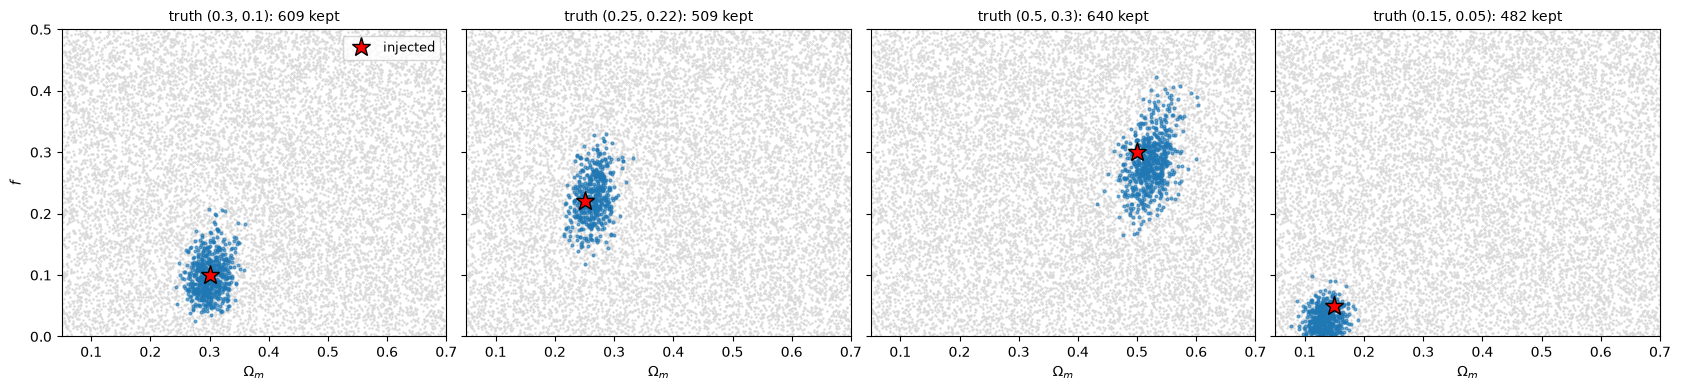

In [8]:
# ----------------------------------------------------------------
# Verification: inject a known (Om, f), run the whole ABC, see if we get it back
# ----------------------------------------------------------------
TRUTHS = [(0.30, 0.10), (0.25, 0.22), (0.50, 0.30), (0.15, 0.05)]   # (Om, f) to inject
N_REP = 5                                   # independent fake files per truth
MIN_KEPT_INJ = 30                           # below this, flag the result as unreliable
rng_inj = np.random.default_rng(42)

def abc_posterior(z_, m_, tol=TOL_FINAL):
    """The same ABC as for the real data: summaries of this file, same tolerance, same cached simulations."""
    S_t = summaries(z_, m_)
    kk = np.all(np.abs(S_sim - S_t) <= np.asarray(tol), axis=1)
    return kk, S_t

results = []                                # one dict per fake file
first_rep = {}                              # kept draws of replicate 0 for each truth, for the plot
for (Om_t, f_t) in TRUTHS:
    for rep in range(N_REP):
        z_f, m_f = simulate(Om_t, f_t, rng_inj)          # a fresh file made at the chosen truth
        kk, S_t = abc_posterior(z_f, m_f)
        n = int(kk.sum())
        if n >= 5:
            lo, med, hi = np.quantile(theta[kk], [0.025, 0.5, 0.975], axis=0)    # each has [Om, f]
        else:
            lo = med = hi = np.array([np.nan, np.nan])
        results.append(dict(Om_t=Om_t, f_t=f_t, rep=rep, n=n, lo=lo, med=med, hi=hi,
                            in_Om=bool(lo[0] <= Om_t <= hi[0]), in_f=bool(lo[1] <= f_t <= hi[1])))
        if rep == 0:
            first_rep[(Om_t, f_t)] = theta[kk]

# Per-file table
print(f"{'truth (Om, f)':>14s} {'rep':>3s} {'kept':>5s}   {'Om median [95% interval]':>28s}  in?   {'f median [95% interval]':>26s}  in?")
for r in results:
    flag = '' if r['n'] >= MIN_KEPT_INJ else '  <-- few draws'
    print(f"({r['Om_t']:.2f}, {r['f_t']:.2f}) {r['rep']:>3d} {r['n']:>5d}   "
          f"{r['med'][0]:8.3f} [{r['lo'][0]:.3f}, {r['hi'][0]:.3f}]  {'yes' if r['in_Om'] else ' NO'}   "
          f"{r['med'][1]:8.3f} [{r['lo'][1]:.3f}, {r['hi'][1]:.3f}]  {'yes' if r['in_f'] else ' NO'}{flag}")

# Summary per truth, and overall
print("\nfraction of replicates whose 95% interval contains the injected value")
for (Om_t, f_t) in TRUTHS:
    rs = [r for r in results if (r['Om_t'], r['f_t']) == (Om_t, f_t)]
    print(f"({Om_t:.2f}, {f_t:.2f}): Om {np.mean([r['in_Om'] for r in rs]):.0%}, f {np.mean([r['in_f'] for r in rs]):.0%}"
          f"   (mean bias: Om {np.nanmean([r['med'][0] - Om_t for r in rs]):+.3f}, f {np.nanmean([r['med'][1] - f_t for r in rs]):+.3f})")
print(f"overall: Om {np.mean([r['in_Om'] for r in results]):.0%}, f {np.mean([r['in_f'] for r in results]):.0%} "
      f"of {len(results)} fake files")

# Kept draws for the first replicate of each truth, with the injected value marked
fig, axes = plt.subplots(1, len(TRUTHS), figsize=(4.2 * len(TRUTHS), 4), sharey=True)
for ax, (Om_t, f_t) in zip(np.atleast_1d(axes), TRUTHS):
    th_k = first_rep[(Om_t, f_t)]
    ax.plot(theta[::20, 0], theta[::20, 1], '.', ms=1.5, color='0.85', rasterized=True)
    ax.plot(th_k[:, 0], th_k[:, 1], '.', ms=4, color='C0', alpha=0.6)
    ax.plot(Om_t, f_t, 'r*', ms=14, mec='k', label='injected')
    ax.set_xlim(OM_RANGE); ax.set_ylim(F_RANGE)
    ax.set_xlabel(r'$\Omega_m$'); ax.set_title(f'truth ({Om_t}, {f_t}): {len(th_k)} kept', fontsize=10)
np.atleast_1d(axes)[0].set_ylabel(r'$f$'); np.atleast_1d(axes)[0].legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.show()